# Exploring Combine Tracking

Player and ball tracking data captured during combine drills, sampled every 0.1 s. All data is taken from [here](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027/data). Columns are position (`x`, `y`, yds), speed (`s`, yds/s), acceleration (`a`, yds/s²), distance since last frame (`dis`, yds) and direction (`dir`, deg).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## combine_tracking.csv

In [2]:
df = pd.read_csv("../data/combine_tracking.csv")
df.head().style.format(precision=2).set_caption("First Rows")

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
0,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.200,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.79,28.29,0.22,0.68,0.01,250.28
1,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.300,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.72,28.30,0.33,0.62,0.00,257.32
2,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.400,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.63,28.28,0.48,0.60,0.01,253.18
3,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.500,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.54,28.24,0.60,0.66,0.01,247.04
4,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.600,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.47,28.21,0.66,0.91,0.01,240.62


In [3]:
print(len(df)) # total number of frames in dataset
print(df["nfl_id"].nunique()) # number of distinct players
print(df["entity_type"].value_counts())

463189
510
entity_type
PLAYER    431094
BALL       32095
Name: count, dtype: int64


In [4]:
positions = pd.read_csv("../data/combine_results.csv", usecols=["nfl_id", "combine_position"])
df = df.merge(positions, on="nfl_id", how="left")

masks = {
    "TE": df["combine_position"] == "TE",
    "DB": df["combine_position"] == "DB",
    "WR": df["combine_position"] == "WR",
    "DL": df["combine_position"] == "DL",
    "OL": df["combine_position"] == "OL",
}

A single rep of a drill is identified by `(event_id, nfl_id, drill_name, attempt)`.

In [5]:
rep_keys = ["event_id", "nfl_id", "drill_name", "attempt"]
reps = df[df["entity_type"] == "PLAYER"].groupby(rep_keys)
print(reps.ngroups) # total number of drill reps

6310


### Drills

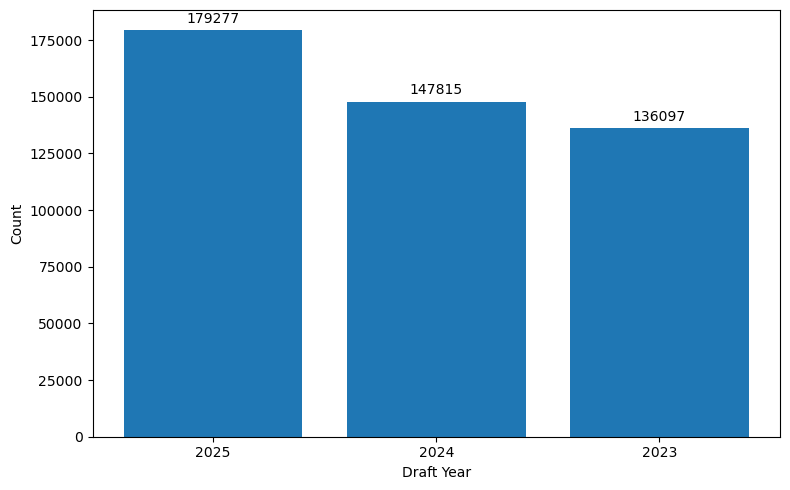

In [6]:
counts = df["draft_year"].value_counts()

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Draft Year")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

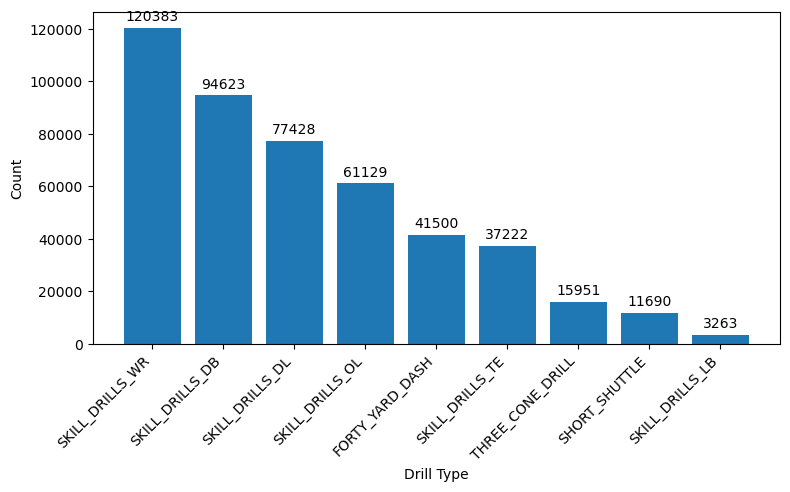

In [7]:
counts = df["drill_type"].value_counts()

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Drill Type")
ax.set_ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [8]:
pd.crosstab(df["drill_type"], df["combine_position"])

combine_position,DB,DL,OL,TE,WR
drill_type,,,,,
FORTY_YARD_DASH,9749,9421,10060,3401,8869
SHORT_SHUTTLE,1977,2299,3522,2065,1827
SKILL_DRILLS_DB,94623,0,0,0,0
SKILL_DRILLS_DL,0,77428,0,0,0
SKILL_DRILLS_LB,0,3263,0,0,0
SKILL_DRILLS_OL,0,0,61129,0,0
SKILL_DRILLS_TE,0,0,0,37222,0
SKILL_DRILLS_WR,0,0,0,0,120383
THREE_CONE_DRILL,2301,4713,4389,2144,2404


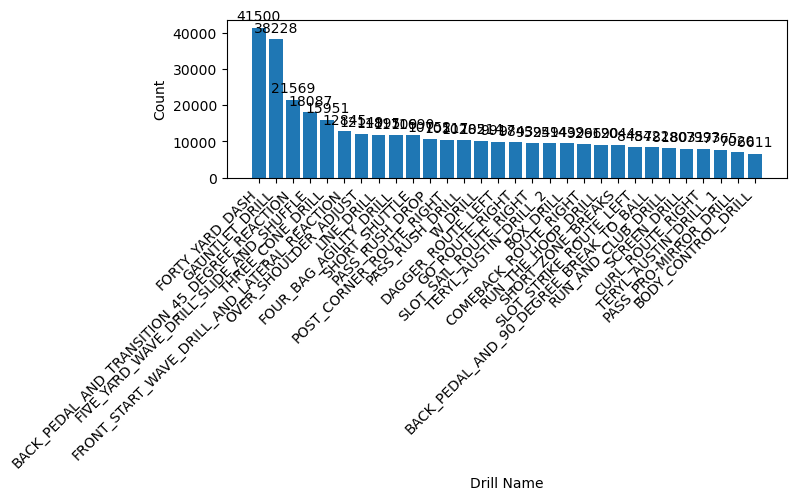

In [9]:
counts = df["drill_name"].value_counts().head(30)

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Drill Name")
ax.set_ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

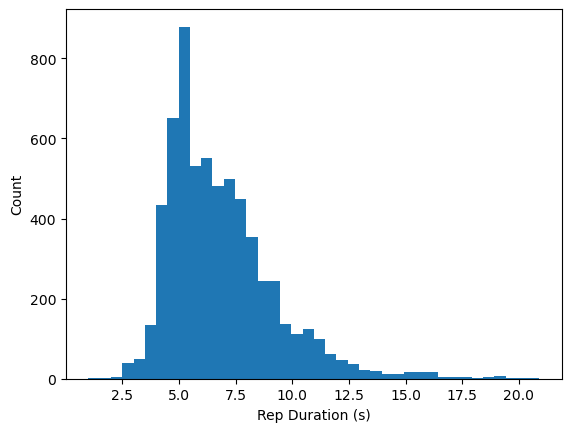

In [10]:
plt.hist(reps.size() / 10, bins=40)
plt.xlabel("Rep Duration (s)")
plt.ylabel("Count");

### Kinematics

In [11]:
players = df[df["entity_type"] == "PLAYER"]
masks = {name: players["combine_position"] == name for name in masks}

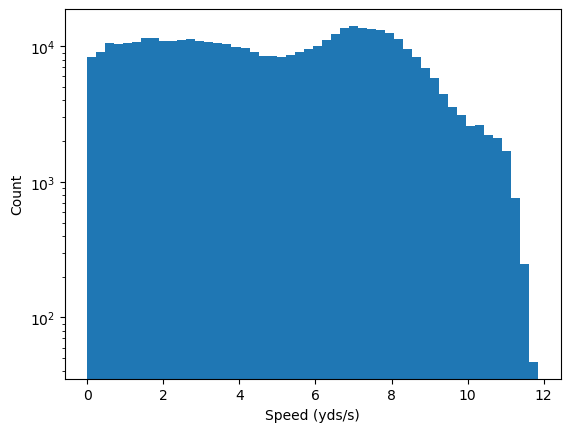

In [12]:
plt.hist(players["s"].dropna(), bins=50)
plt.xlabel("Speed (yds/s)")
plt.ylabel("Count")
plt.yscale("log");

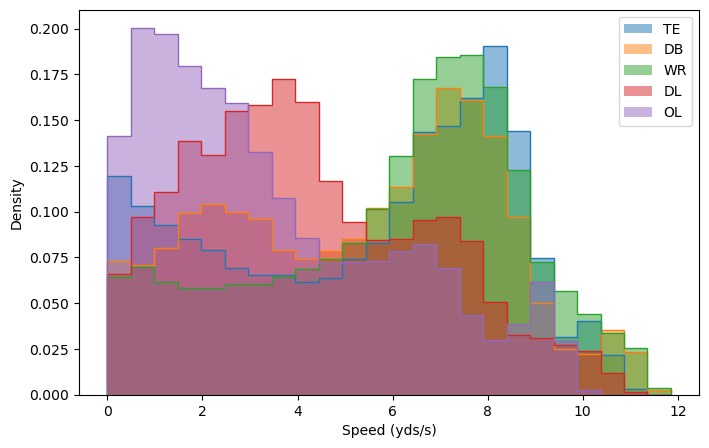

In [13]:
bins = np.linspace(players["s"].min(), players["s"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    if players.loc[m, "s"].isna().all():
        continue
    color = f"C{i}"
    ax.hist(players.loc[m, "s"], bins=bins, histtype="step", color=color, density=True)
    ax.hist(players.loc[m, "s"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5, density=True)

ax.set_xlabel("Speed (yds/s)")
ax.set_ylabel("Density")
ax.legend()
plt.show()

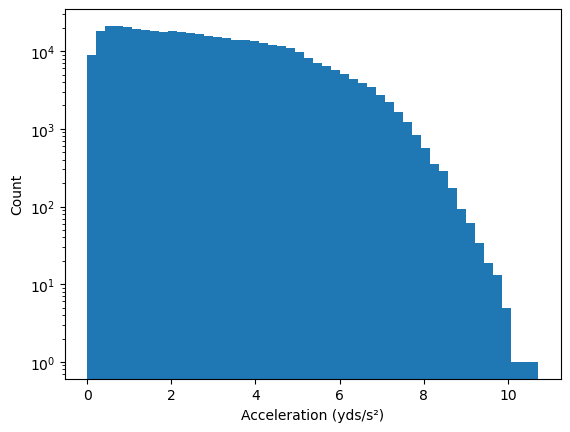

In [14]:
plt.hist(players["a"].dropna(), bins=50)
plt.xlabel("Acceleration (yds/s²)")
plt.ylabel("Count")
plt.yscale("log");

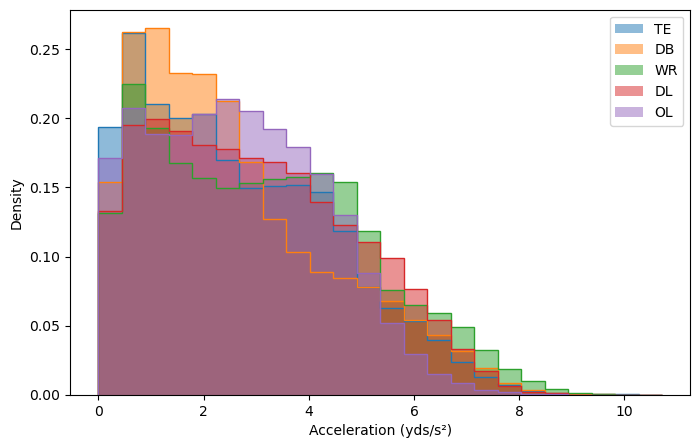

In [15]:
bins = np.linspace(players["a"].min(), players["a"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    if players.loc[m, "a"].isna().all():
        continue
    color = f"C{i}"
    ax.hist(players.loc[m, "a"], bins=bins, histtype="step", color=color, density=True)
    ax.hist(players.loc[m, "a"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5, density=True)

ax.set_xlabel("Acceleration (yds/s²)")
ax.set_ylabel("Density")
ax.legend()
plt.show()

### Forty Yard Dash

A single example rep:

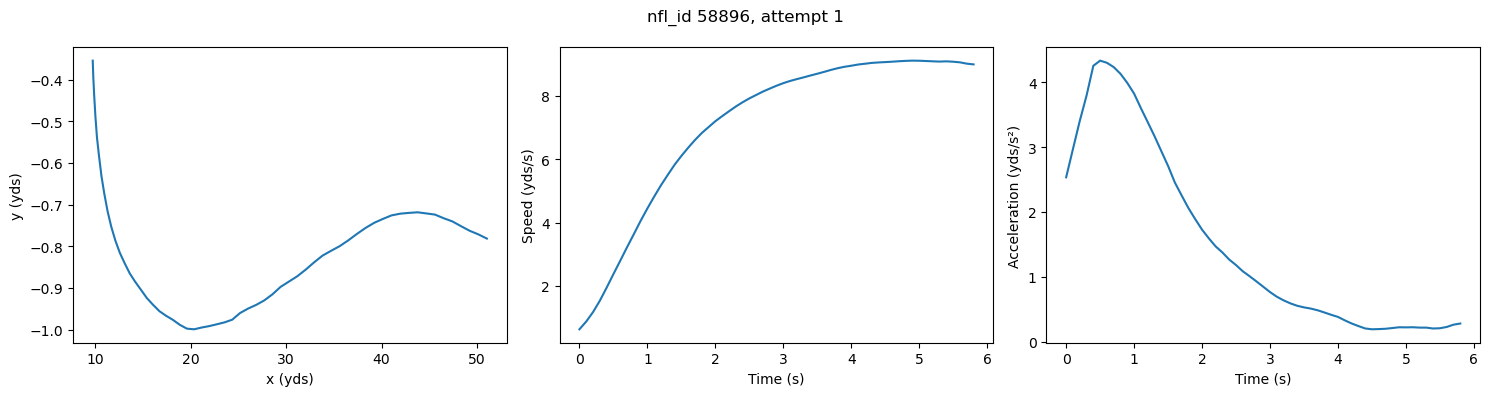

In [16]:
forty = players[players["drill_type"] == "FORTY_YARD_DASH"]
example_key = forty[rep_keys].iloc[0]
example = forty[(forty[rep_keys] == example_key).all(axis=1)]
t = (pd.to_datetime(example["time"]) - pd.to_datetime(example["time"]).iloc[0]).dt.total_seconds()

fig, axes = plt.subplots(1, 3, figsize=(15,4))
axes[0].plot(example["x"], example["y"])
axes[0].set_xlabel("x (yds)")
axes[0].set_ylabel("y (yds)")
axes[1].plot(t, example["s"])
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Speed (yds/s)")
axes[2].plot(t, example["a"])
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Acceleration (yds/s²)")
fig.suptitle(f"nfl_id {example_key['nfl_id']}, attempt {example_key['attempt']}")
plt.tight_layout()
plt.show()

Each player's top speed across all their forty reps, compared with their official forty time from `combine_results.csv`.

In [17]:
top_speed = forty.groupby("nfl_id")["s"].max().rename("forty_max_speed").reset_index()
results = pd.read_csv("../data/combine_results.csv", usecols=["nfl_id", "combine_position", "forty"])
top_speed = top_speed.merge(results, on="nfl_id", how="left")
print(len(top_speed)) # players with forty tracking

418


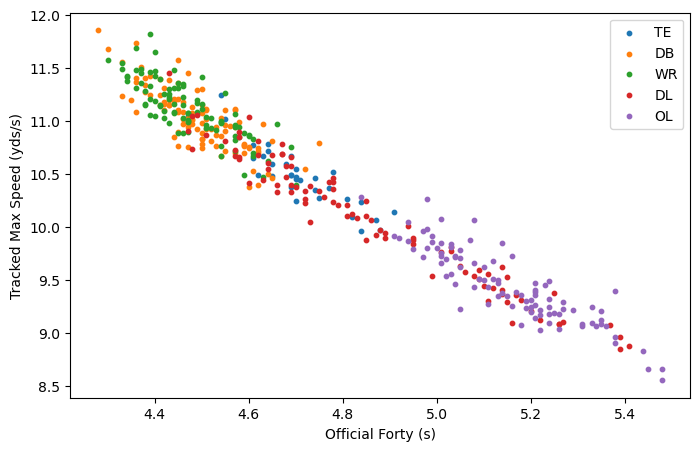

In [18]:
fig, ax = plt.subplots(figsize=(8,5))
for i, name in enumerate(masks):
    m = top_speed["combine_position"] == name
    ax.scatter(top_speed.loc[m, "forty"], top_speed.loc[m, "forty_max_speed"], s=10, label=name, color=f"C{i}")
ax.set_xlabel("Official Forty (s)")
ax.set_ylabel("Tracked Max Speed (yds/s)")
ax.legend()
plt.show()

### Positional Drills

Max speed per player within their position-specific skill drills.

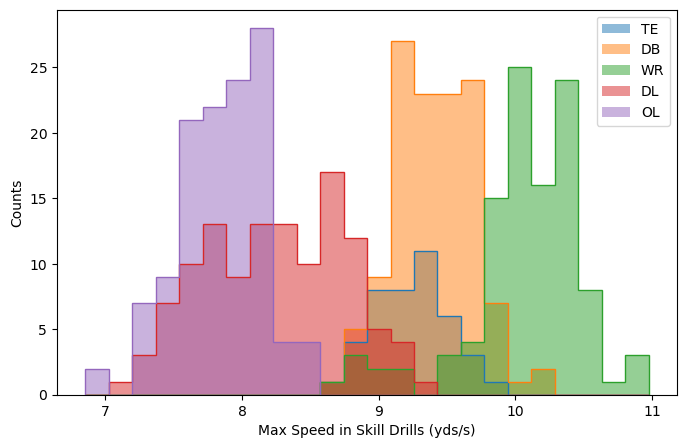

In [19]:
skill = players[players["drill_type"].str.startswith("SKILL_DRILLS")]
skill_speed = skill.groupby(["nfl_id", "combine_position"])["s"].max().rename("skill_max_speed").reset_index()

fig, ax = plt.subplots(figsize=(8,5))
bins = np.linspace(skill_speed["skill_max_speed"].min(), skill_speed["skill_max_speed"].max(), 25)
for i, name in enumerate(masks):
    m = skill_speed["combine_position"] == name
    ax.hist(skill_speed.loc[m, "skill_max_speed"], bins=bins, histtype="step", color=f"C{i}")
    ax.hist(skill_speed.loc[m, "skill_max_speed"], bins=bins, histtype="stepfilled", label=name, color=f"C{i}", alpha=0.5)
ax.set_xlabel("Max Speed in Skill Drills (yds/s)")
ax.set_ylabel("Counts")
ax.legend()
plt.show()

Example trajectories (player, plus ball when the drill tracks one) for one rep of the most common drill for each position group.

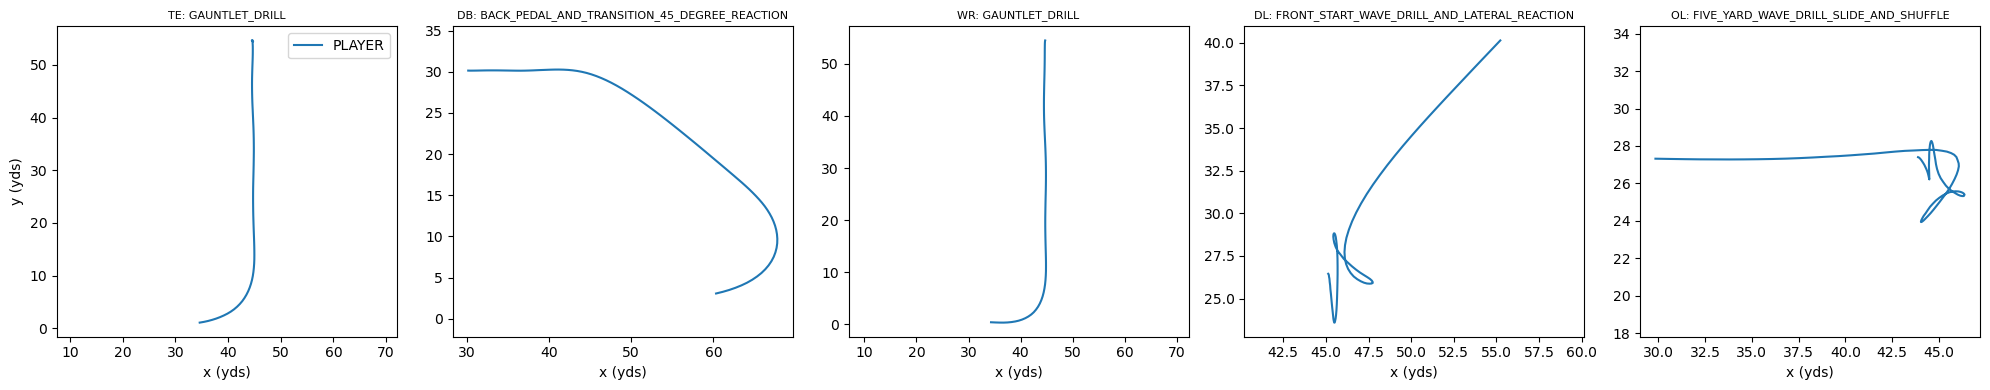

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(20,4))
for ax, name in zip(axes, masks):
    group = skill[skill["combine_position"] == name]
    drill = group["drill_name"].value_counts().index[0]
    key = group.loc[group["drill_name"] == drill, rep_keys].iloc[0]
    rep = df[(df[rep_keys] == key).all(axis=1)]
    for entity, e in rep.groupby("entity_type"):
        ax.plot(e["x"], e["y"], label=entity)
    ax.set_title(f"{name}: {drill}", fontsize=8)
    ax.set_xlabel("x (yds)")
    ax.set_aspect("equal", adjustable="datalim")
axes[0].set_ylabel("y (yds)")
axes[0].legend()
plt.tight_layout()
plt.show()